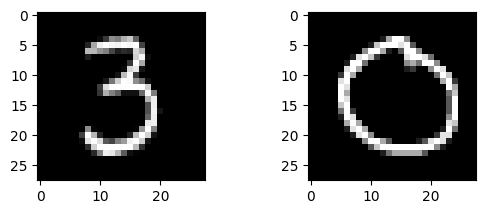

In [1]:
from keras.models import Sequential
from keras.layers import Flatten, Dense, Dropout, Conv2D, MaxPooling2D
from keras.utils import to_categorical
from keras.datasets import mnist
from keras import backend as K
from keras.optimizers import Adam, RMSprop, SGD

import matplotlib.pyplot as plt
import numpy as np

# K.set_image_data_format('channels_first')
K.set_image_data_format("channels_last")

# Load images of handwritten-digits
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Take a look at two of the images.
plt.subplot(221)
plt.imshow(X_train[50], cmap=plt.get_cmap("gray"))
plt.subplot(222)
plt.imshow(X_train[68], cmap=plt.get_cmap("gray"))
plt.show()

In [2]:
# Load images of handwritten-digits
(X_train, y_train), (X_test, y_test) = mnist.load_data()

The size of X_train is N by Width by Height (you can use shape to get the sizes).
Use reshape to change the size of X_train to N by 1 by Width by Height. Similarly do the same thing for X_test 

In [3]:
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], X_train.shape[2], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], X_test.shape[2], 1)

Each pixle is between 0 and 255, normalize the image by making the pixles between 0 and 1 by dividing by 255. 

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

Make y a hot vector. by using np_utils.to_categorical

In [5]:
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [6]:
number_of_classes = y_test.shape[1]

In [7]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print(number_of_classes)

(60000, 28, 28, 1)
(10000, 28, 28, 1)
(60000, 10)
(10000, 10)
10


Create a multi-layer convolutional neural network in the following way: 

For the first layer create 40 convolutional networks with window sizes of 5 by 5, and ReLu for the activation. 

Add a max pooling layer with a window of 2 by 2. 

For the second layer create 30 colvolutional networks with window sizes of 3 by 3, ReLu for the activation. 

Add a max pooling layer with a window of 2 by 2. 

For the third layer create 20 colvolutional networks with window sizes of 2 by 2, ReLu for the activation. 

Add a max pooling layer with a window of 2 by 2. 

Flatten the last layer. 

For the forth layer use a Dense layer of size 60 with ReLu for activation

For the fifth layer use a Dense layer of size number_of_classes with softmax for activation 

Use categorical_crossentropy for loss and adam for optimizer, 10 for epochs and 80 for batch_size

In [8]:
# Create the convolutional neural network
model = Sequential()

# First convolutional layer: 40 filters, 5x5 window, ReLU
model.add(Conv2D(40, kernel_size=(5, 5), activation="relu", input_shape=(28, 28, 1)))

# First max pooling layer: 2x2
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second convolutional layer: 30 filters, 3x3 window, ReLU
model.add(Conv2D(30, kernel_size=(3, 3), activation="relu"))

# Second max pooling layer: 2x2
model.add(MaxPooling2D(pool_size=(2, 2)))

# Third convolutional layer: 20 filters, 2x2 window, ReLU
model.add(Conv2D(20, kernel_size=(2, 2), activation="relu"))

# Third max pooling layer: 2x2
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten
model.add(Flatten())

# Fourth layer: Dense 60, ReLU
model.add(Dense(60, activation="relu"))

# Fifth layer: Dense number_of_classes, Softmax
model.add(Dense(number_of_classes, activation="softmax"))

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Train the model
history = model.fit(
    X_train, y_train, epochs=10, batch_size=80, validation_data=(X_test, y_test)
)

c:\Users\Vesal\Documents\Code\Python\Jupyter\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9074 - loss: 0.2958 - val_accuracy: 0.9734 - val_loss: 0.0850
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9728 - loss: 0.0856 - val_accuracy: 0.9756 - val_loss: 0.0738
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9796 - loss: 0.0645 - val_accuracy: 0.9877 - val_loss: 0.0449
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9850 - loss: 0.0502 - val_accuracy: 0.9856 - val_loss: 0.0435
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9870 - loss: 0.0428 - val_accuracy: 0.9864 - val_loss: 0.0454
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9883 - loss: 0.0376 - val_accuracy: 0.9869 - val_loss: 0.0379
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9892 - loss: 0.0342 - val_accuracy: 0.9906 - val_loss: 0.0303
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9903 - loss: 0.0303 - val_accu

In [9]:
# Compute the accuracy of the model on X_test and y_test
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", test_accuracy)

# Add dropouts of 0.10 right after your max pooling layer. Do you get a better result?
model_dropout = Sequential()

model_dropout.add(
    Conv2D(40, kernel_size=(5, 5), activation="relu", input_shape=(28, 28, 1))
)
model_dropout.add(MaxPooling2D(pool_size=(2, 2)))
model_dropout.add(Dropout(0.10))

model_dropout.add(Conv2D(30, kernel_size=(3, 3), activation="relu"))
model_dropout.add(MaxPooling2D(pool_size=(2, 2)))
model_dropout.add(Dropout(0.10))

model_dropout.add(Conv2D(20, kernel_size=(2, 2), activation="relu"))
model_dropout.add(MaxPooling2D(pool_size=(2, 2)))
model_dropout.add(Dropout(0.10))

model_dropout.add(Flatten())
model_dropout.add(Dense(60, activation="relu"))
model_dropout.add(Dense(number_of_classes, activation="softmax"))

model_dropout.compile(
    loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"]
)

history_dropout = model_dropout.fit(
    X_train, y_train, epochs=10, batch_size=80, validation_data=(X_test, y_test)
)

dropout_loss, dropout_accuracy = model_dropout.evaluate(X_test, y_test, verbose=0)

print("Test accuracy with dropout:", dropout_accuracy)

# What accuracy do you get when using RMSprop for your optimizer?
model_rmsprop = Sequential()

model_rmsprop.add(
    Conv2D(40, kernel_size=(5, 5), activation="relu", input_shape=(28, 28, 1))
)
model_rmsprop.add(MaxPooling2D(pool_size=(2, 2)))

model_rmsprop.add(Conv2D(30, kernel_size=(3, 3), activation="relu"))
model_rmsprop.add(MaxPooling2D(pool_size=(2, 2)))

model_rmsprop.add(Conv2D(20, kernel_size=(2, 2), activation="relu"))
model_rmsprop.add(MaxPooling2D(pool_size=(2, 2)))

model_rmsprop.add(Flatten())
model_rmsprop.add(Dense(60, activation="relu"))
model_rmsprop.add(Dense(number_of_classes, activation="softmax"))

model_rmsprop.compile(
    loss="categorical_crossentropy", optimizer="rmsprop", metrics=["accuracy"]
)

history_rmsprop = model_rmsprop.fit(
    X_train, y_train, epochs=10, batch_size=80, validation_data=(X_test, y_test)
)

rmsprop_loss, rmsprop_accuracy = model_rmsprop.evaluate(X_test, y_test, verbose=0)

print("Test accuracy with RMSprop:", rmsprop_accuracy)

# What accuracy do you get when using SGD for your optimizer?
model_sgd = Sequential()

model_sgd.add(
    Conv2D(40, kernel_size=(5, 5), activation="relu", input_shape=(28, 28, 1))
)
model_sgd.add(MaxPooling2D(pool_size=(2, 2)))

model_sgd.add(Conv2D(30, kernel_size=(3, 3), activation="relu"))
model_sgd.add(MaxPooling2D(pool_size=(2, 2)))

model_sgd.add(Conv2D(20, kernel_size=(2, 2), activation="relu"))
model_sgd.add(MaxPooling2D(pool_size=(2, 2)))

model_sgd.add(Flatten())
model_sgd.add(Dense(60, activation="relu"))
model_sgd.add(Dense(number_of_classes, activation="softmax"))

model_sgd.compile(
    loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"]
)

history_sgd = model_sgd.fit(
    X_train, y_train, epochs=10, batch_size=80, validation_data=(X_test, y_test)
)

sgd_loss, sgd_accuracy = model_sgd.evaluate(X_test, y_test, verbose=0)

print("Test accuracy with SGD:", sgd_accuracy)

Test accuracy: 0.9898999929428101
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8761 - loss: 0.3847 - val_accuracy: 0.9722 - val_loss: 0.0866
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9624 - loss: 0.1189 - val_accuracy: 0.9818 - val_loss: 0.0535
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9724 - loss: 0.0876 - val_accuracy: 0.9859 - val_loss: 0.0425
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9774 - loss: 0.0728 - val_accuracy: 0.9884 - val_loss: 0.0369
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9805 - loss: 0.0622 - val_accuracy: 0.9897 - val_loss: 0.0312
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9822 - loss: 0.0568 - val_accuracy: 0.9902 - val_loss: 0.0307
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9840 - loss: 0.0515 - val_accuracy: 0.9918 - val_loss: 0.0249
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accurac

In [10]:
print("====================================")
print("RESULTS")
print("====================================")
print("Adam accuracy:      ", test_accuracy)
print("Adam + Dropout:     ", dropout_accuracy)
print("RMSprop accuracy:   ", rmsprop_accuracy)
print("SGD accuracy:       ", sgd_accuracy)

RESULTS
Adam accuracy:       0.9898999929428101
Adam + Dropout:      0.9922999739646912
RMSprop accuracy:    0.986299991607666
SGD accuracy:        0.9781000018119812
